In [440]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from torchmetrics import Accuracy
from torch import optim
from torch.utils.data import DataLoader, TensorDataset,Dataset
from dotenv import load_dotenv
from datetime import datetime, timedelta
import os
import requests
load_dotenv()

True

In [441]:

headers = {
    "accept": "application/json",
    "x-cg-demo-api-key": str(os.getenv('COIN_API'))
}

In [442]:
response_1 = requests.get(
    "https://api.coingecko.com/api/v3/coins/bitcoin/market_chart?vs_currency=usd&days=90",
    headers=headers
)

data = response_1.json()

# Convert prices to DataFrame
df_prices = pd.DataFrame(data['prices'], columns=['timestamp', 'price'])
df_prices['timestamp'] = pd.to_datetime(df_prices['timestamp'], unit='ms')

# Convert market caps to DataFrame
df_mcap = pd.DataFrame(data['market_caps'], columns=['timestamp', 'market_cap'])
df_mcap['timestamp'] = pd.to_datetime(df_mcap['timestamp'], unit='ms')

# Convert volumes to DataFrame
df_volume = pd.DataFrame(data['total_volumes'], columns=['timestamp', 'volume'])
df_volume['timestamp'] = pd.to_datetime(df_volume['timestamp'], unit='ms')

# Merge all into one DataFrame
df_combined = df_prices.merge(df_mcap, on='timestamp').merge(df_volume, on='timestamp')

# --- Returns (this is your new prediction target) -

df_combined

,timestamp,price,market_cap,volume
0,2026-05-05 20:00:00,81627.415083,1.634600e+12,3.701947e+10
1,2026-05-05 21:00:00,81644.471711,1.634946e+12,3.715901e+10
2,2026-05-05 22:00:00,81473.677967,1.631526e+12,3.844943e+10
3,2026-05-05 23:00:00,81130.269199,1.624649e+12,3.891131e+10
4,2026-05-06 00:00:00,80913.961375,1.620322e+12,3.963153e+10
...,...,...,...,...
2156,2026-08-03 16:00:00,63616.510598,1.276480e+12,2.342019e+10
2157,2026-08-03 17:00:00,63711.080959,1.278378e+12,2.422042e+10
2158,2026-08-03 18:00:00,63843.499850,1.281036e+12,2.477577e+10
2159,2026-08-03 19:00:00,63812.896022,1.280423e+12,2.473630e+10


               price  market_cap    volume
price       1.000000    0.999994  0.034018
market_cap  0.999994    1.000000  0.032611
volume      0.034018    0.032611  1.000000


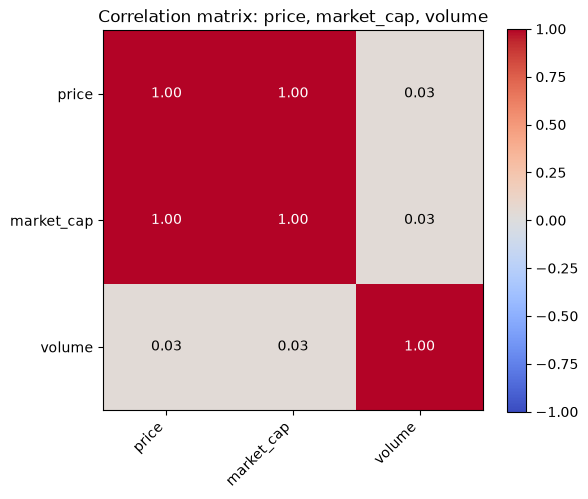

In [443]:
import matplotlib.pyplot as plt
 
# Pearson correlation matrix (default method for .corr())
corr = df_combined[["price", "market_cap", "volume"]].corr()
print(corr)
 
# --- Heatmap so you can see the strength at a glance ---
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
 
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
ax.set_title("Correlation matrix: price, market_cap, volume")
 
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}",
                ha="center", va="center",
                color="white" if abs(corr.values[i, j]) > 0.5 else "black")
 
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


In [ ]:
#values = df_combined[["price", "volume", "market_cap","open",'high','low','close']].to_numpy(dtype=np.float32)
values = df_combined[["price", "volume", "market_cap"]].to_numpy(dtype=np.float32)

train_end = int(len(values) * 0.7)
val_end = int(len(values) * 0.85)

train = values[:train_end]
val = values[train_end:val_end]
test = values[val_end:]

# Fit scaler on TRAIN only
mean = train.mean(axis=0)
std = train.std(axis=0)
std[std == 0] = 1.0

train = (train - mean) / std
val = (val - mean) / std
test = (test - mean) / std

def windows(data, seq_len=30):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i:i + seq_len])
        y.append(data[i + seq_len, 0])  # next price
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)

X_train, y_train = windows(train)
X_val, y_val = windows(val)
X_test, y_test = windows(test)

print(X_train.shape)
print(X_val.shape)

class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

train_dataset = TimeSeriesDataset(X_train, y_train)
val_dataset = TimeSeriesDataset(X_val, y_val)
test_dataset = TimeSeriesDataset(X_test, y_test)

train_data_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_data_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_data_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


(1482, 30, 3)
(294, 30, 3)


In [445]:
class Model(nn.Module):
    def __init__(self, input_size,hidden_size,num_stacked_layers,batch_first=True):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_stacked_layers = num_stacked_layers
        self.lstm = nn.LSTM(self.input_size,hidden_size,self.num_stacked_layers,batch_first=batch_first)
        self.final = nn.Linear(hidden_size,1)

    def forward(self,x):
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_stacked_layers,batch_size,self.hidden_size)
        c0 = torch.zeros(self.num_stacked_layers,batch_size,self.hidden_size)
        out, _ = self.lstm(x,(h0,c0))
        out = self.final(out[:,-1,:])
        return out

model = Model(X_train.shape[-1], hidden_size=5, num_stacked_layers=1)
model

Model(
  (lstm): LSTM(3, 5, batch_first=True)
  (final): Linear(in_features=5, out_features=1, bias=True)
)

In [446]:
def train_model(model, train_loader, val_loader, optimizer, criterion, epoch, num_epochs,training_loss,testing_loss):
    model.train()
    train_loss = 0.0

    for feature, label in train_loader:
        optimizer.zero_grad()
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    training_loss.append(avg_train_loss)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for feature, label in val_loader:
            pred = model(feature).squeeze(-1)
            loss = criterion(pred, label)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    testing_loss.append(avg_val_loss)

    print(f"Epoch {epoch + 1}/{num_epochs} - train_loss: {avg_train_loss:.6f} - val_loss: {avg_val_loss:.6f}")

Epoch 1/100 - train_loss: 0.344492 - val_loss: 0.027605
Epoch 2/100 - train_loss: 0.030568 - val_loss: 0.002178
Epoch 3/100 - train_loss: 0.004282 - val_loss: 0.001190
Epoch 4/100 - train_loss: 0.002847 - val_loss: 0.000946
Epoch 5/100 - train_loss: 0.002539 - val_loss: 0.001003
Epoch 6/100 - train_loss: 0.002419 - val_loss: 0.000979
Epoch 7/100 - train_loss: 0.002266 - val_loss: 0.001057
Epoch 8/100 - train_loss: 0.002184 - val_loss: 0.000851
Epoch 9/100 - train_loss: 0.002165 - val_loss: 0.000910
Epoch 10/100 - train_loss: 0.002196 - val_loss: 0.000872
Epoch 11/100 - train_loss: 0.002133 - val_loss: 0.000950
Epoch 12/100 - train_loss: 0.002240 - val_loss: 0.000756
Epoch 13/100 - train_loss: 0.001927 - val_loss: 0.000814
Epoch 14/100 - train_loss: 0.001821 - val_loss: 0.000771
Epoch 15/100 - train_loss: 0.001878 - val_loss: 0.000924
Epoch 16/100 - train_loss: 0.001879 - val_loss: 0.000807
Epoch 17/100 - train_loss: 0.001867 - val_loss: 0.000828
Epoch 18/100 - train_loss: 0.001929 - va

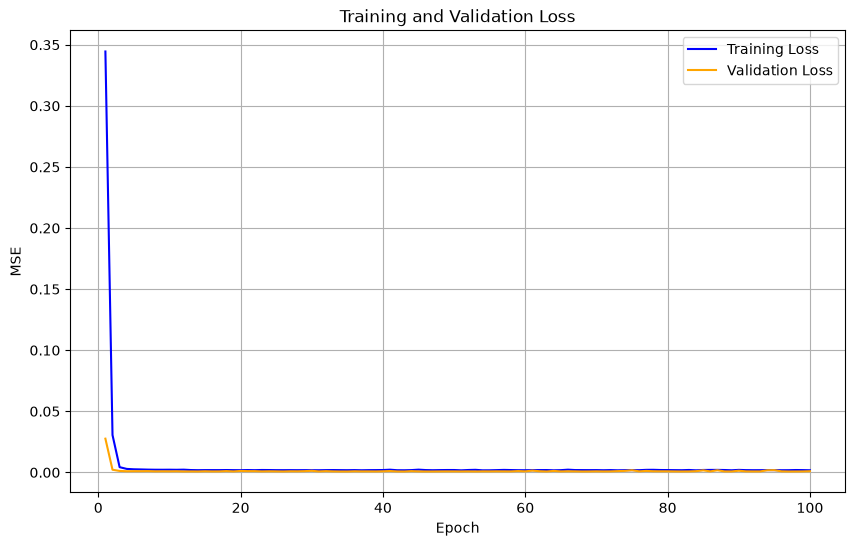

In [447]:
import matplotlib.pyplot as plt

learning_rate = 0.01
num_epochs = 100
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)

training_loss = []
testing_loss = []

for epoch in range(num_epochs):
    train_model(
        model,
        train_data_loader,
        val_data_loader,
        optimizer,
        criterion,
        epoch,
        num_epochs,
        training_loss,
        testing_loss
    )

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(training_loss) + 1), training_loss, label="Training Loss", color="blue")
plt.plot(range(1, len(testing_loss) + 1), testing_loss, label="Validation Loss", color="orange")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [448]:
model.eval()

test_loss = 0.0
with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        loss = criterion(pred, label)
        test_loss += loss.item()

avg_test_loss = test_loss / len(test_data_loader)
print(f"Test loss: {avg_test_loss:.6f}")

Test loss: 0.000866


In [449]:
model.eval()

# Save the original price scaling before normalization
price_mean = df_combined["price"].mean()
price_std = df_combined["price"].std()

all_preds = []
all_true = []

with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        
        # convert from normalized space back to real price space
        pred_price = pred.cpu().numpy() * price_std + price_mean
        true_price = label.cpu().numpy() * price_std + price_mean
        
        all_preds.append(pred_price)
        all_true.append(true_price)

all_preds = np.concatenate(all_preds)
all_true = np.concatenate(all_true)

# Real dollar-scale metrics
rmse = np.sqrt(np.mean((all_preds - all_true) ** 2))
mae = np.mean(np.abs(all_preds - all_true))

print(f"Test MSE (normalized): {avg_test_loss:.6f}")
print(f"Test RMSE (USD): ${rmse:,.2f}")
print(f"Test MAE (USD): ${mae:,.2f}")

# Optional: print first few predictions
for p, t in zip(all_preds[:5], all_true[:5]):
    print(f"Pred: ${p:,.2f} | Actual: ${t:,.2f}")

Test MSE (normalized): 0.000866
Test RMSE (USD): $189.64
Test MAE (USD): $134.76
Pred: $64,289.37 | Actual: $64,723.14
Pred: $64,610.72 | Actual: $64,588.85
Pred: $64,464.69 | Actual: $64,814.38
Pred: $64,713.47 | Actual: $64,983.16
Pred: $64,891.43 | Actual: $64,801.27


In [450]:
model.eval()
 
# IMPORTANT fix: un-scale with the SAME mean/std the model was trained with
# (the `mean`/`std` arrays from your data-prep cell; index 0 = price column).
# Using df_combined-wide stats biases the USD values by a couple hundred dollars.
price_mean = mean[0]
price_std  = std[0]
 
all_preds = []
all_true = []
all_prev = []   # NEW: the last price the model saw before predicting
 
test_loss = 0.0  # NEW: normalized test loss, computed here so no NameError
 
with torch.no_grad():
    for feature, label in test_data_loader:
        pred = model(feature).squeeze(-1)
        test_loss += criterion(pred, label).item()
 
        # convert from normalized space back to real price space
        pred_price = pred.cpu().numpy() * price_std + price_mean
        true_price = label.cpu().numpy() * price_std + price_mean
 
        # NEW: "previous price" = last step of the window, price is column 0
        prev_price = feature[:, -1, 0].cpu().numpy() * price_std + price_mean
 
        all_preds.append(pred_price)
        all_true.append(true_price)
        all_prev.append(prev_price)
 
all_preds = np.concatenate(all_preds)
all_true  = np.concatenate(all_true)
all_prev  = np.concatenate(all_prev)
 
# Real dollar-scale metrics
rmse = np.sqrt(np.mean((all_preds - all_true) ** 2))
mae  = np.mean(np.abs(all_preds - all_true))
 
# NEW: the hypothesis test — how good is "just copy the previous close"?
copy_rmse  = np.sqrt(np.mean((all_prev - all_true) ** 2))
copy_mae   = np.mean(np.abs(all_prev - all_true))
beats_copy = np.mean(np.abs(all_preds - all_true) < np.abs(all_prev - all_true))
 
print(f"Test MSE (normalized): {test_loss / len(test_data_loader):.6f}")
print(f"Test RMSE (USD): ${rmse:,.2f} | MAE (USD): ${mae:,.2f}")
print(f"Baseline (copy previous close): RMSE ${copy_rmse:,.2f} | MAE ${copy_mae:,.2f}")
print(f"Model beats 'copy previous close' on {beats_copy * 100:.1f}% of test windows")
 
# The table: Prev = last close the model saw | Pred = its guess | Actual = what happened
print("\n  Prev (last seen) |  Predicted   |   Actual")
for p, t, prev in zip(all_preds[:8], all_true[:8], all_prev[:8]):
    print(f"  ${prev:,.2f}   | ${p:,.2f} | ${t:,.2f}")

Test MSE (normalized): 0.000866
Test RMSE (USD): $212.56 | MAE (USD): $151.05
Baseline (copy previous close): RMSE $202.21 | MAE $136.81
Model beats 'copy previous close' on 41.0% of test windows

  Prev (last seen) |  Predicted   |   Actual
  $65,589.34   | $65,418.51 | $65,904.71
  $65,904.71   | $65,778.70 | $65,754.19
  $65,754.19   | $65,615.02 | $66,006.98
  $66,006.98   | $65,893.88 | $66,196.17
  $66,196.17   | $66,093.35 | $65,992.29
  $65,992.29   | $65,868.29 | $65,865.88
  $65,865.88   | $65,731.09 | $65,886.78
  $65,886.78   | $65,760.93 | $65,888.67


In [451]:
'''
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "learning_rate": learning_rate,
    "num_epochs": num_epochs,
    "mean": mean,
    "std": std,
    "price_mean": price_mean,
    "price_std": price_std,
    "training_loss": training_loss,
    "testing_loss": testing_loss,
    "rmse_usd": rmse,
    "mae_usd": mae
}, "bitcoin_lstm_model.pt")

'''

'\ntorch.save({\n    "model_state_dict": model.state_dict(),\n    "optimizer_state_dict": optimizer.state_dict(),\n    "learning_rate": learning_rate,\n    "num_epochs": num_epochs,\n    "mean": mean,\n    "std": std,\n    "price_mean": price_mean,\n    "price_std": price_std,\n    "training_loss": training_loss,\n    "testing_loss": testing_loss,\n    "rmse_usd": rmse,\n    "mae_usd": mae\n}, "bitcoin_lstm_model.pt")\n\n'

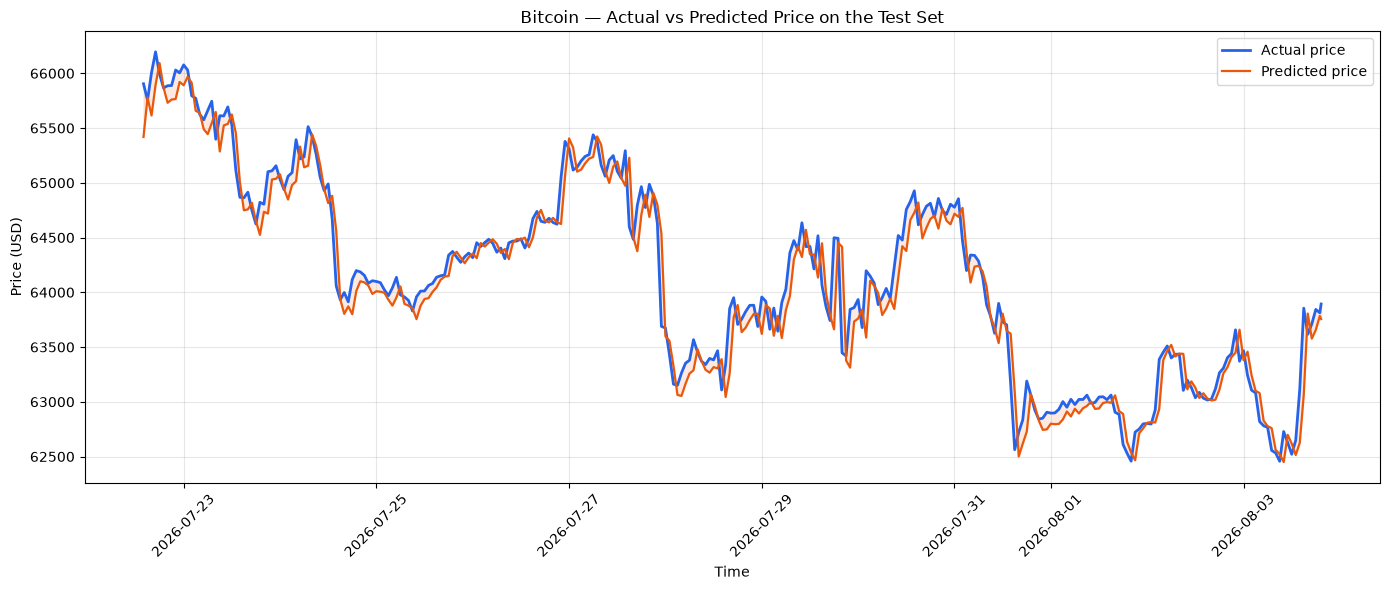

In [452]:
# Map each test prediction back to its real timestamp.
# Prediction i targets the price at test row i + 30, which is
# global row (val_end + 30 + i) of df_combined — i.e. the last
# len(all_true) timestamps of the dataset.
test_timestamps = df_combined["timestamp"].iloc[
    val_end + 30 : val_end + 30 + len(all_true)
].reset_index(drop=True)
 
plt.figure(figsize=(14, 6))
 
plt.plot(test_timestamps, all_true,  label="Actual price",   color="#2563eb", linewidth=2)
plt.plot(test_timestamps, all_preds, label="Predicted price", color="#ea580c", linewidth=1.6)
 
# Shade the gap between the lines — that IS the prediction error
plt.fill_between(test_timestamps, all_true, all_preds, color="#ea580c", alpha=0.12)
 
plt.xlabel("Time")
plt.ylabel("Price (USD)")
plt.title("Bitcoin — Actual vs Predicted Price on the Test Set")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()